<a href="https://colab.research.google.com/github/Ale-yo/POD-ElectronDynamics-Schrodinger/blob/main/Electron_Dynamics_POD-Galerkin_Alessia_Cecchini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Assignment 1: Catching electrons in a bi-crystal**

*Alessia Cecchini* \
*Model Order Reduction Techniques* \
MSc in Mechanical Engineering, Politecnico di Milano

The code below is only partially showing the satisfactory results obtained with a passionate reasoning over the implementation strategies, leveraging the knowledge and tools acquired during the course.

\The model used to describe the electron position in the bi-crystal is described through a Schrodinger equation, where at time $t =0$ the wave function of the electron is $$\Psi(x) := e^{-100\left\|x\right\|^{2}}.$$

The entire analysis is based on the Schrodinger equation:

$$i\hbar \frac{\partial \Psi}{\partial t} = -\frac{\hbar^2}{2m}\,\Delta \Psi + V_{\mu}\Psi,$$

where

$$V_{\mu}(x) = E^{\top}x + \Delta V_{0}\,\mathbf{1}_{[0,+\infty)}(x_{2}),$$

and the parameters vectors is

$$\mu := [E,\Delta V_{0}] \ \text{and} \  E, ΔV_{0} \in [0, 1000]$$

In [ ]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
clc()

# **FOM CODE (from the professor)**




In [ ]:
## Construction of the geometry
domain = fe.circle((0, 0), 1.0/np.pi)
mesh = fe.mesh(domain, stepsize = 0.02)
Vh = fe.space(mesh, 'CG', 1)
nh = Vh.dim()
clc()

## Definition of the Full Order Model (FOM)
def FOMsolver(E, deltaV0, steps = 99, dt = 1e-3):
  from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression
  from scipy.sparse.linalg import spsolve
  from scipy.sparse import bmat

  # System's characteristics and matrices
  potential = fe.interpolate(lambda x: E*(x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0)) + deltaV0*(x[1] > 0), Vh)

  S = fe.assemble(lambda u, v: inner(grad(u), grad(v))*dx, Vh)                   # STIFFNESS matrix
  M = fe.assemble(lambda u, v: u*v*dx, Vh)                                       # MASS matrix
  V = fe.assemble(lambda u, v: potential*u*v*dx, Vh)                             # POTENTIAL matrix

  # Boundary Conditions
  bc = fe.DirichletBC(lambda x: True, 0.0)
  B = S + V
  B = fe.applyBCs(B, Vh, bc)
  M = fe.applyBCs(M, Vh, bc)

  A = bmat([[M, -dt*B], [dt*B, M]])
  M2 = bmat([[M, 0*M], [0*M, M]])                                    # matrice massa per il sistema; 0*M per garantire dimensioni (altrimenti avresti un solo scalare)

  u0_real = fe.interpolate(lambda x: np.exp(-100*(x[0]**2+x[1]**2)), Vh)
  u0_imag = fe.interpolate(0.0, Vh)
  u0_real_vec = fe.dofs(u0_real)
  u0_imag_vec = fe.dofs(u0_imag)
  states = [np.concatenate((u0_real_vec, u0_imag_vec))]               # concatenare parte reale e immaginaria

  # DEVELOP THE MATRIX BY ADDING CONTINUOUSLY THE TIME INFORMATION
  for n in range(steps):                                                        # for each time interval
    now = states[-1]
    rhs = M2 @ now                                                              # consider the very last state (i.e. the present)
    rhs[:nh] = fe.applyBCs(rhs[:nh], Vh, bc)                                    # for the new interval time, we calculate the mass matrix (update) and leave BC = 0; # spsolve allows to solve the linear system
    rhs[nh:] = fe.applyBCs(rhs[nh:], Vh, bc)
    next = spsolve(A, rhs)
    states.append(next)                                                         # append the new info
  clc()
  return np.stack(states)                                                       # it transforms the list in a matrix (rows = time ; FEM dofs)
# il codice sopra sostituisce questo sotto
  # for n in range(steps):
  #   now = states[-1]
  #   next = spsolve(A, fe.applyBCs(M2 @ now, Vh, bc))
  #   states.append(next)
  # clc()
  # return np.stack(states)

## Auxiliary functions for Task (iii)
from fenics import dx
M = fe.assemble(lambda u, v: u*v*dx, Vh)
clc()

def probabilities(u):
  unnormalized_probabilities = (u.reshape(-1, 2, nh)**2).sum(axis = 1)
  integrals = (unnormalized_probabilities @ M).sum(axis = -1)                   # (3000,)
  return unnormalized_probabilities/integrals.reshape(-1, 1)                    # obtain a matrix (3000x995)

def caught(prob):
  T = 0.1
  times = np.linspace(0, T, 100)
  indicator = fe.dofs(fe.interpolate(lambda x: x[1]>0, Vh))
  return (prob @ M @ indicator).mean()

In [ ]:
print(f"dimension of Vh is {nh}")

dimension of Vh is 995


# **1) SVD and POD BASIS CREATION**

In this point, to select properly the dimension of the reduced space, and so the dimension of the matrix $V$ that allows to move in it, is necessary to exploit Singular Value Decomposition. That fundamental step is however performed only after having selected a set of FOM solutions, starting from values of the parameters randomically picked.

The data generation section not only goes with the definition of parameters, but also with the assembly of the vectors $\mathbf{\mu}$ and $\mathbf{u}$. From this, the first pecularity of the exercise comes out: the description of the electron position is exploited in the $\mathbb{C}$ set. This implies that the dimension of $\mathbf{u}$ is twice the one of the FOM space, as real and imaginary parts should both be addressed.



## Data loading



To allow anyone with a view-only link to execute this notebook quickly without running the full FOM simulations, you can pre-save the `mu` and `u` data to Google Drive. Follow these steps:

1.  **Run the `np.savez` cell below** (it's currently commented out, but I'll uncomment it).
2.  **Locate the generated `ACassignment1.npz` file** in your Colab environment (usually `/content/ACassignment1.npz`).
3.  **Upload this file to your Google Drive.**
4.  **Change the sharing options** of the uploaded file to "Anyone with the link" (view-only).
5.  **Get the file ID** from the shared link. The ID is the part of the URL after `d/` and before `/view` (e.g., `https://drive.google.com/file/d/<FILE_ID>/view?usp=sharing`).
6.  **Paste the `FILE_ID`** into the `gdown.download` call in the next code cell.
7.  **Run the following code cell** to download and load the data. The subsequent data generation cell will then skip re-running the FOM simulations if the data is successfully loaded.

In [ ]:
import os
import gdown

# You can use the full sharing URL, and the code will attempt to extract the ID.
GOOGLE_DRIVE_LINK_OR_ID = 'https://drive.google.com/file/d/1Koe1o2nveIzZrm0B-EJLpzdyexRZbxKb/view?usp=sharing'

# Extract just the ID if a full link is provided
if 'drive.google.com/file/d/' in GOOGLE_DRIVE_LINK_OR_ID:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID.split('/d/')[1].split('/view')[0]
else:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID

# Check if the file exists locally or if a valid Google Drive ID is provided
if os.path.exists('ACassignment1.npz'):
    print("Loading data from existing 'ACassignment1.npz' file...")
    data_loaded = True
elif GOOGLE_DRIVE_FILE_ID and GOOGLE_DRIVE_FILE_ID != 'YOUR_GOOGLE_DRIVE_FILE_ID':
    print(f"Downloading 'ACassignment1.npz' from Google Drive ID: {GOOGLE_DRIVE_FILE_ID}...")
    try:
        gdown.download(id=GOOGLE_DRIVE_FILE_ID, output="ACassignment1.npz", quiet=False)
        data_loaded = True
    except Exception as e:
        print(f"Error downloading file: {e}")
        print("Proceeding with data generation.")
        data_loaded = False
else:
    print("No pre-saved data found or Google Drive ID provided. Proceeding with data generation.")
    data_loaded = False

if data_loaded:
    print("Loading data from 'ACassignment1.npz'...")
    data = np.load('ACassignment1.npz')
    mu = data['mu']
    u = data['u']
    if 'Es' in data.files and 'Ps' in data.files and 'Es_total' in data.files and 'Ps_total' in data.files:
        Es = data['Es']
        Ps = data['Ps']
        Es_total = data['Es_total']
        Ps_total = data['Ps_total']
    print("Data loaded successfully!")


Downloading...
From (original): https://drive.google.com/uc?id=1Koe1o2nveIzZrm0B-EJLpzdyexRZbxKb
From (redirected): https://drive.google.com/uc?id=1Koe1o2nveIzZrm0B-EJLpzdyexRZbxKb&confirm=t&uuid=9dda3a32-194d-47c9-9a79-50d47c76fa95
To: /content/ACassignment1.npz
100%|██████████| 47.8M/47.8M [00:00<00:00, 78.8MB/s]


Loading data from 'ACassignment1.npz'...
Data loaded successfully!


In [ ]:
if not data_loaded:
    print("Generating new data...")
    # Data generation
    # values of the parameters range from 0 to 1000
    # have 2 parameters: E and V0

    nsamples = 30                                                                   # number of samples
    muList = []                                                                    # list of parameters
    uList = []                                                                     # list of solutions evaluated (based on mu) with FOM model
    for i in range(nsamples):
      E = 1000*np.random.rand()                                                    # get random values in 0 - 1, multiply by 1000 to get them between 0 and 1000
      deltaV0 = 1000*np.random.rand()                                              # define get random values in 0 - 1, multiply by 1000 to get them between 0 and 1000
      mu_current = np.array([E, deltaV0])                                          # create the vector of parameters
      u_current = FOMsolver(mu_current[0], mu_current[1])                          # pass E and deltaV0 separately
      muList.append(mu_current)                                                    #adding values to list
      uList.append(u_current)                                                      #adding values to list

    mu = np.stack(muList)
    u = np.stack(uList)

    print(f"The number of trajectories is {u.shape} (u)")
    print(f"The number of parameters is {mu.shape} (mu)")
else:
    print("Skipping data generation as data was loaded from file.")
    # mu and u are already loaded
    nsamples = mu.shape[0] # Define nsamples from the loaded data

Skipping data generation as data was loaded from file.


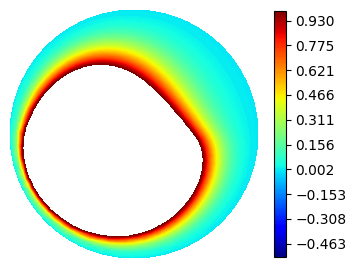

In [ ]:
# Plot the FOM solution
fe.multiplot(probabilities(u[1, -1, :]), (1, 1), Vh, colorbar = True, vmin = u.min(), vmax = u.max())

## Perform SVD

Taking half the training data, the associated matrix $U_{train}$ is taken as snaposhots matrix with respect to which SVD is performed.

Plotting the decay of the singular values, will then be possible to determine the proper number of singular values according to their energetic content (i.e. amount of information that they contain).

The chosen number of singular values, by looking at their decay, is $n = 30$. It is straightforward to affirm:
$ V_n \in \mathbb{R^{N_h \times n}} $

In [ ]:
# Divide the samples in 15 for training and 15 for testing

from scipy.linalg import svd                                                    # to do Singular Value Decomposition
ntrain = nsamples//2                                                            # divide to obtain 15 samples for training

ndata, nt, nh2 = u.shape
Utrain = (u[:ntrain]).reshape(ntrain*nt, nh2).T                                 # want a matrix with dimension nh2 x nsnapshots (nsnapshots = ntrain x num_time_steps)

Utrain.shape

(1990, 1500)

In [ ]:
## SVD

# use the new Utrain matrix to create the vector of singular values

# perform the SVD of the snapshot matrix obtaining the matrices X, Yt of the left and right vectors
# and the vector s containing singular values
# NOTICE: as setting full_matrices = False, the singular values are NOT inserted
# into a matrix along its diagonal, but rather are simply an array

# extracting the first half of simulations on which will make svd
X, s, Yt = svd(Utrain, full_matrices = False)
X.shape, s.shape

# s is so a vector with size corresponding to the number of snapshots

((1990, 1500), (1500,))

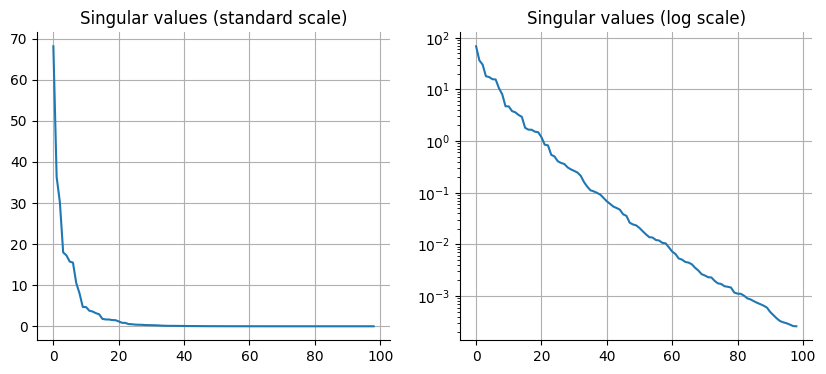

In [ ]:
# Plot the singular values
import matplotlib.pyplot as plt

# Plot in decimal scale
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(s[1:100])
plt.title('Singular values (standard scale)')
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Plot in logarithmic scale
plt.subplot(1,2,2)
plt.plot(s[1:100])
plt.yscale('log')
plt.title('Singular values (log scale)')
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


## Create POD basis

In [ ]:
# Create the POD basis Vn

n = 30            # number of singular values considered - based on plot above

Vn = X[: , :n]    # define the reduced basis as the first n columns of the matrix of the left eigenvectors
Vn.shape

(1990, 30)

# **2) POD-Galerkin ROM**

## ROM IMPLEMENTATION


In order to implement the Reduced Order Modeling with POD-Galerkin, the following steps have been performed:


1.  Precomputation of those matrices that can be precomputed, in order to reduce the computational effort as the RB solver is implemented. Indeed, being the problem under analysis a time-dependent case, it would be completely useless, as time expensive, to compute each time the matrices - i.e. to assemble them. To do this, an obstacle comes out: the parameters dependency of an element in the matrix (specifically, the potential). However, this was not big issue, after an elaborate reasoning, since the parameter dependence was affine, so the separation of their contribution from the whole matrix is possible, only requiring few code lines;
2.   Apply the homogenous Dirchilet boundary conditions to all the involved matrices at the high-dimension space ($N_h$);
3.   Perform the Galerkin reduced basis projection, moving to the reduced dimension $n=30$ with the POD basis;
4.  At this point, the _online_ phase starts: as parameters are introduced into our system, the solution is computed. The time is taken into account by considering the Backward Euler implementation, which allows to move step by step further in time and to solve in the RB space the PDE - which is now nothing but a linear system, thanks to POD-Galerkin;
5.  To conclude, is necessary to move back to the FOM dimension, and again the POD basis helps with it.

### Matrix precomputation

In [ ]:
from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression      # importing the libraries
from scipy.sparse.linalg import spsolve                                                   # importing the libraries
from scipy.sparse import bmat                                                             # importing the libraries

dt = 1e-3
steps = 99
bc = fe.DirichletBC(lambda x: True, 0.0)

## PRECOMPUTE THE MATRICEs ##
S = fe.assemble(lambda u, v: inner(grad(u), grad(v))*dx, Vh)                    # STIFFNESS matrix
M = fe.assemble(lambda u, v: u*v*dx, Vh)                                        # MASS matrix

# Exploit the affine dependence on parameters E and ΔV0
# separate the contributions in the potential
# consider the space over which they're defined
potE = fe.interpolate(lambda x: x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0), Vh)      # contribution of electric field - interpolate over Vh
potV0 = fe.interpolate(lambda x: (x[1] > 0), Vh)                                # contribution of ΔV0 - interpolate over Vh

# define the contributions of V = E*Eh + deltaV0*deltaV0h --- where E and deltaV0 are the parameters
Eh = fe.assemble(lambda u, v: potE*u*v*dx, Vh)
deltaV0h = fe.assemble(lambda u, v: potV0*u*v*dx, Vh)

# Boundary conditions
S = fe.applyBCs(S, Vh, bc)
M = fe.applyBCs(M, Vh, bc)
Eh = fe.applyBCs(Eh, Vh, bc)
deltaV0h = fe.applyBCs(deltaV0h, Vh, bc)

# build the associated block matrices (size 1990x1990)
M2 = bmat([[M, 0*M], [0*M, M]])
Sblock = bmat([[0*S, S], [-S, 0*S]])
Eh_block = bmat([[0*Eh, Eh], [-Eh, 0*Eh]])
deltaV0h_block = bmat([[0*deltaV0h, deltaV0h], [-deltaV0h, 0*deltaV0h]])
#Eh_block.shape, deltaV0h_block.shape

S.shape, M.shape, Sblock.shape, M2.shape
#print(f'the size of the matrices S and M is: {S.shape, M.shape}, while their block form has size {Sblock.shape, M2.shape}')

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling form ffc_form_797f5b8a558921976f103fe39a96895ac5a846d4

INFO:FFC:Compiler stage 1: Analyzing form(s)
INFO:FFC:-----------------------------------
DEBUG:FFC:  Preprocessing form using 'uflacs' representation family.
INFO:FFC:  
INFO:FFC:  Geometric dimension:       2
  Number of cell subdomains: 0
  Rank:                      2
  Arguments:                 '(v_0, v_1)'
  Number of coefficients:    0
  Coefficients:              '[]'
  Unique elements:           'CG1(?,?), Vector<2 x CG1(?,?)>'
  Unique sub elements:       'CG1(?,?), Vector<2 x CG1(?,?)>'
  
INFO:FFC:  representation:    auto --> uflacs
INFO:FFC:  quadrature_rule:   auto --> default
INFO:FFC:  quadrature_degree: auto --> 0
INFO:FFC:  quadrature_degree: 0
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.0393736 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-----------------------------

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling form ffc_form_e6fe2f6d559447784d4e273c082f0dc8668ca1d5

INFO:FFC:Compiler stage 1: Analyzing form(s)
INFO:FFC:-----------------------------------
DEBUG:FFC:  Preprocessing form using 'uflacs' representation family.
INFO:FFC:  
INFO:FFC:  Geometric dimension:       2
  Number of cell subdomains: 0
  Rank:                      2
  Arguments:                 '(v_0, v_1)'
  Number of coefficients:    1
  Coefficients:              '[f_17]'
  Unique elements:           'CG1(?,?), Vector<2 x CG1(?,?)>'
  Unique sub elements:       'CG1(?,?), Vector<2 x CG1(?,?)>'
  
INFO:FFC:  representation:    auto --> uflacs
INFO:FFC:  quadrature_rule:   auto --> default
INFO:FFC:  quadrature_degree: auto --> 3
INFO:FFC:  quadrature_degree: 3
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.0284207 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------

((995, 995), (995, 995), (1990, 1990), (1990, 1990))

### Reduction of matrices

In [ ]:
# Galerkin projection
# Reduce the precomputed matrices
Mrb = Vn.T @ M2 @ Vn    # reduce the block mass matrix
Srb = Vn.T @ Sblock @ Vn
Erb = Vn.T @ Eh_block @ Vn
deltaV0rb = Vn.T @ deltaV0h_block @ Vn

print(f"The shape of the reduced mass matrix, stiffness matrix, potential due to electric field and due to potential difference is, respectively, {Mrb.shape, Srb.shape, Erb.shape, deltaV0rb.shape}")

The shape of the reduced mass matrix, stiffness matrix, potential due to electric field and due to potential difference is, respectively, ((30, 30), (30, 30), (30, 30), (30, 30))


### ONLINE: Reduced evolution scheme (Backward Euler)

In [ ]:
# Reduced evolution scheme using Backward Euler

# Exploit affine parametrization to assemble the matrix B
def RBstep(psi_now, dt, mu):                                                    # phi_now refer to actual state of function, used to move further;
  # Define the parameters from mu vector
  E, deltaV0 = mu[0], mu[1]
  # assemble the matrix --- notice that all the pieces are already been subjected to boundary conditions
  Brb = E*Erb + deltaV0*deltaV0rb + Srb

  return  np.linalg.solve(Mrb - dt*Brb, Mrb @ psi_now)       # obiettivo: trovare psi_now+1

### ONLINE: RB solver

In [ ]:
## RB solver - pass to the previous function the psi_now iteratively

# define the initial solution u0 (from FOM)
u0_real = fe.interpolate(lambda x: np.exp(-100*(x[0]**2+x[1]**2)), Vh)
u0_imag = fe.interpolate(0.0, Vh)
u0_real_vec = fe.dofs(u0_real)
u0_imag_vec = fe.dofs(u0_imag)
u0 = np.concatenate((u0_real_vec, u0_imag_vec))

def RBsolver(mu, dt = 1e-3, steps=99):
     # project initial condition
     psi0 = Vn.T @ u0                                                           # dimensioni: (30,) -- NB: è un vettore 1D per numpy

     # time loop in reduced space and add elements to psi
     psi = [psi0]
     for n in range(steps):
       psi_new = RBstep(psi[-1], dt, mu)
       psi.append(psi_new)
     psi = np.stack(psi, axis = 0)

     # move back to FOM
     u = psi @ Vn.T                                                             #(nsteps+1, n) @ (n, nh2) --> (nsteps+1, nh2)

     return u

In [ ]:
# Check the dimension of reduced solution

mu0 = np.array([600, 400])
uRB = RBsolver(mu0, dt, steps)
uRB.shape                                                                       # expect to be (nsteps+1, nh2)

(100, 1990)

 ## EFFICIENCY ANALYSIS

The efficiency analysis constists in comparing the difference in computational time between FOM and ROM solutions, to highlight the convenience of ROM.

### Computational time FOM vs ROM

In [ ]:
## Analyze the computational time - efficiency

# Define vector of parameters
mu0 = np.array([1000*np.random.rand(), 1000*np.random.rand()])

# Import required libraries
from time import perf_counter

# Computational time RB
t0 = perf_counter()
uRB = RBsolver(mu0, dt, steps)
t1 = perf_counter()
dtROM = t1 - t0

# Computational time FOM
t2 = perf_counter()
uFOM = FOMsolver(mu0[0], mu0[1])
t3 = perf_counter()
dtFOM = t3 - t2


print(f'The computational time for ROM solution is {(t1 - t0):.3f}s while the computational time for FOM solution is {(t3 - t2):.3f}s, given E = {mu0[0]:.2f} N/C, \u0394V0 = {mu0[1]:.2f} V.')
print(f'The difference in computational time of the two solutions is {(t3-t2)-(t1 - t0):.3f} s')
print("\n>> Boost: x%d." % (dtFOM//dtROM))

The computational time for ROM solution is 0.022s while the computational time for FOM solution is 4.858s, given E = 149.36 N/C, ΔV0 = 107.11 V.
The difference in computational time of the two solutions is 4.836 s

>> Boost: x222.


In [ ]:
uRB.shape, uFOM.shape

((100, 1990), (100, 1990))

## ACCURACY ANALYSIS

The accuracy analysis allows us to compare how good are the results that has been obtained with POD-Galerkin. It is evaluated over the set of data identified as testing - that is, over those data that have not been used to build up the RB architecture.

The **relative error** is computed as:
$$E_{\text{test}}=\frac{1}{N_{\text{h}}}\sum_{j=1}^{N_{\text{h}}}\left(\max_{k=0,\dots,N_t}\;\frac{\|\mathbf{u}_{j,k}^{\text{test}}-\mathbf{u}_{\boldsymbol{\mu}^{\text{test}}_{j}, k}^{rb}\|}{\|\mathbf{u}_{j,k}^{\text{test}}\|}\right)$$

and its result is then plotted over time.

Then, to evaluate the spread of the error over the test set, median and quantiles are computed, with respect to the error computed over the FOM space:
$$E=\frac{1}{N_{\text{h}}}\sum_{j=1}^{N_{\text{h}}}\left(\frac{\|\mathbf{u}_{j}^{\text{test}}-\mathbf{u}_{\boldsymbol{\mu}^{\text{test}}_{j}}^{rb}\|}{\|\mathbf{u}_{j}^{\text{test}}\|}\right)$$

### Relative error

In [ ]:
# Take the data for evaluating the relative error
# Data from FOM (test)
utest = u[ntrain:]

# Data from RB solution
uRBtest = [RBsolver(m) for m in mu[ntrain:]]                                    # it creates a list of solutions from RB
uRBtest = np.stack(uRBtest)                                                     # create a matrix from the list
uRBtest.shape, utest.shape

((15, 100, 1990), (15, 100, 1990))

In [ ]:
## Calculate the average relative error - computed with respect to the test set

# Calculate the average error
avgerror = np.linalg.norm(uFOM - uRB, axis = 1)/np.linalg.norm(uFOM, axis = 1)           # mean over the space (1990) - it becomes a vector (100,)
print("Average error is: %s." % num2p(avgerror[ntrain:].mean()))                         # mean of the average errors over the test set

# Calculate the relative error
errors = np.linalg.norm(utest-uRBtest, axis = - 1)/np.linalg.norm(utest, axis = -1)      # mean over the space (1990) - it becomes a matrix(15, 100)
etest = errors.max(axis = - 1).mean()                                                    # mean over the time (100) - it becomes a vector(15,) --- then average to get a scalat
print("Average uniform relative error: %s." % num2p(etest))

Average error is: 0.43%.
Average uniform relative error: 3.12%.


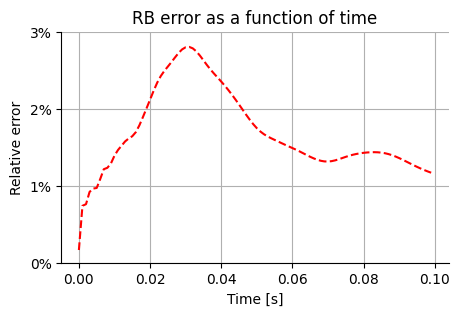

In [ ]:
## Relative error vs Time plot

# Error
errortime = errors.mean(axis = 0)                                               # mean of the errors over the number of ntrain (15) -- get a vector (100,)

# Time
T = dt*steps
t = np.linspace(0, T, len(errortime))

# Plot
plt.figure(figsize = (5, 3))
plt.plot(t, errortime, '--r')
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("RB error as a function of time")
plt.yticks([0, 0.01, 0.02, 0.03], ["0%", "1%", "2%", "3%"])
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

### Spread of the error across the test set

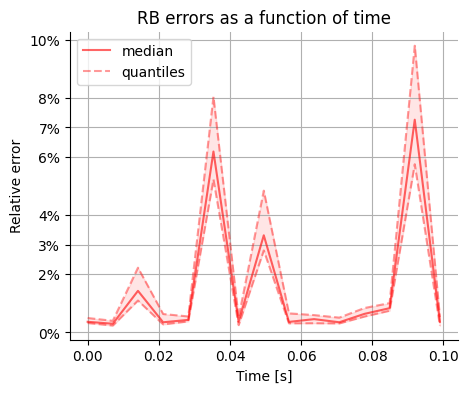

In [ ]:
## Spread of the error across the test set
T = dt*steps
t2 = np.linspace(0, T, len(errors))

errT = errors.T
median = np.quantile(errT, 0.5, axis = 0)
q1 = np.quantile(errT, 0.25, axis = 0)
q3 = np.quantile(errT, 0.75, axis = 0)

plt.figure(figsize = (5, 4))
plt.plot(t2, median, '-r', label = 'median', alpha = 0.6)
plt.plot(t2, q1, '--r', label = 'quantiles', alpha = 0.4)
plt.plot(t2, q3, '--r', alpha = 0.4)
plt.fill_between(t2, q1, q3, color = 'red', alpha = 0.1)
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("RB errors as a function of time")
marks = np.linspace(q1.min(), q3.max(), 8)
marks = [round(mark, 2) for mark in marks]
plt.yticks(marks, [num2p(mark).replace(".00", "") for mark in marks])
#plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05], ["0%", "1%", "2%" ,"3%", "4%", "5%"])
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

# **3) PROBABILITY ANALYSIS**

The third step required to compute the probability to find an electron in the top part of the crystal plate. Considering the formula:
$$
P = \frac{1}{T}
\int_0^T
\int_{C_{\mathrm{top}}}
p_t(x)\, dx\, dt,
\
C_{\mathrm{top}}
=
\{(x_1,x_2)\in\Omega : x_2 > 0\}.
$$

The code to analyze the probability is provided by the professor, and here it was used in combination with the developed RB solver.

The result not only identifies the value of the electric field $E$ to have more than $50 \% %$ of the probability to find the electron in the top plate, but also how such probability changes as the value of $E$ varies among those that satisfy the requirement.

In [ ]:
## Probability of having the electron in top region of the plate
if not data_loaded:
    deltaV0_prob = 100
    # prob >= 50%
    # E = ?

    # Define arrays where solution values will be added to then plot
    Es = np.array([[]])
    Ps = np.array([[]])
    Ps_total = np.array([[]])
    Es_total = np.array([[]])
    for E in range(0, 1000+1):
      muP = [E, deltaV0_prob]                                                       # starting conditions
      uP = RBsolver(muP)
      prob = probabilities(uP)
      presence = caught(prob)
      Ps_total = np.append(Ps_total, presence)
      Es_total = np.append(Es_total, E)
      if presence >= 0.5:
        Es = np.append(Es, E)
        Ps = np.append(Ps, presence)
else:
    print("Using pre-loaded Es, Ps, Es_total, Ps_total from file.")
    Es = data['Es']
    Ps = data['Ps']
    Es_total = data['Es_total']
    Ps_total = data['Ps_total']

Es_fifty = Es[0]
print(f"The value of E, to which corresponds a probability of {100*Ps[0]:.2f} %, is {Es_fifty:.2f}")
#Es.shape, Ps.shape

Using pre-loaded Es, Ps, Es_total, Ps_total from file.
The value of E, to which corresponds a probability of 50.02 %, is 628.00


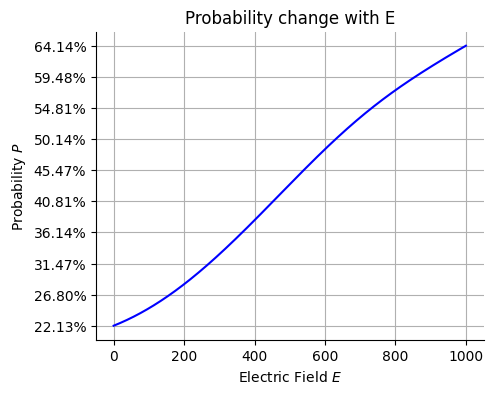

In [ ]:
# Plot the evolution of E vs Probability
plt.figure(figsize = (5, 4))
plt.plot(Es_total, Ps_total, 'b')
plt.xlabel("Electric Field $E$")
plt.ylabel("Probability $P$")
yticks = np.linspace(Ps_total[0], Ps_total[-1], 10)
plt.yticks(yticks, [num2p(tick) for tick in yticks])
plt.title("Probability change with E")
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

# **MORE DETAILED ANALYSIS and FURTHER EXPLORATIONS**

Below, more detailed analysis is performed. The error is analyzed for the whole data set, exploring so how it changes outside the training values and for a time period thatis twice the one addressed above.

Moreover, other explorations have been done, considering also different values for the parameters ($ΔV > 1000$) and different features ($dt = 0.0005, dt = 0.002$).

Last but not least, some plots comparing the FOM and ROM results are shown.

## Error exceeding period of interest

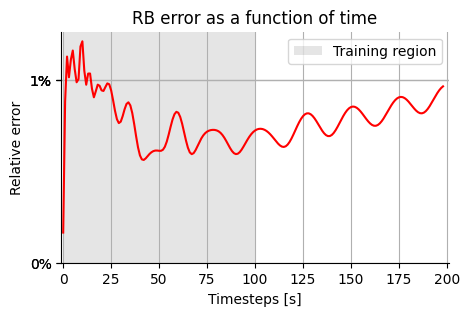

In [ ]:
## Error plot over the period of training - considering timesteps
# Define the new parameters for such analysis
steps2 = steps*2
mustep = np.array([1000*np.random.rand(), 1000*np.random.rand()])
ustep2 = RBsolver(mustep, dt = 1e-3, steps = steps2)
uFOM2 = FOMsolver(mustep[0], mustep[1], steps2, dt)
uFOM2.shape, ustep2.shape

# Compute the error
error2 = np.linalg.norm(uFOM2-ustep2, axis = 1)/np.linalg.norm(uFOM2, axis = 1)    # relative error over time

## Plot
plt.figure(figsize = (5, 3))
plt.plot(error2, 'r')

# Define text
plt.xlabel("Timesteps [s]")
plt.ylabel("Relative error")
plt.title("RB error as a function of time")

# Define region
marks = np.linspace(error2.min(), error2.max(), 6)
marks = [round(mark, 2) for mark in marks]
plt.yticks(marks, [num2p(mark).replace(".00", "") for mark in marks])
ylim = plt.gca().get_ylim()
plt.fill([0, 100, 100, 0], [ylim[0], ylim[0], ylim[1], ylim[1]], 'k', label = "Training region", alpha = 0.1)
plt.axis([-1, 201, *ylim])
# Custom the plot
plt.grid(True)
plt.legend()

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

/tmp/ipykernel_7230/681840660.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


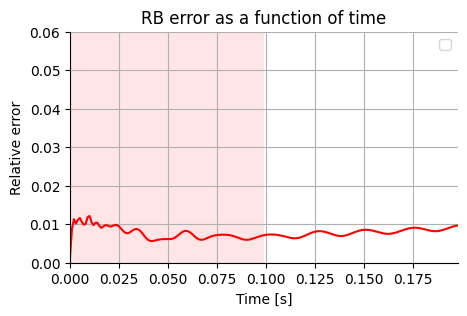

In [ ]:
## Error evolution over time, consider twice the number of steps
# considering time

# Define time vector
T2 = dt*steps2
tstep2 = np.linspace(0, T2, steps2 + 1)                                         # writing steps2 + 1 so to have dimension matching between error and time

## Plot
plt.figure(figsize = (5, 3))
plt.plot(tstep2, error2, 'r')

# Define text
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("RB error as a function of time")

# Custom the plot
plt.grid(True)
plt.legend()

# Define limits of the axes
ylim = [0, 0.06]
plt.axis([0, steps2 * dt, *ylim])
# Fill the steps = 98 = predefined
plt.fill([0, dt*steps, dt*steps, 0], [ylim[0], ylim[0], ylim[1], ylim[1]], 'r', label = "Training region", alpha = 0.1)

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


## Parameters exceeding the training values: ΔV > 1000. How does the relative error change?


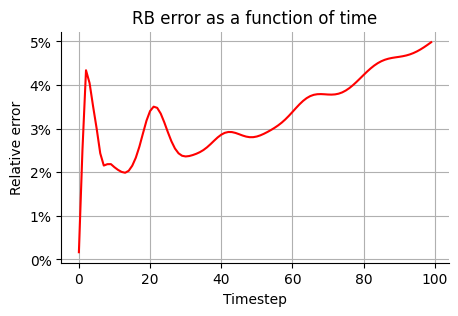

In [ ]:
# Define the parameters
E_exc = 1000*np.random.rand()                                                   # 0 - 1000
deltaV0_exc = 2000                                                              # > 1000
mu_exc = np.array([E_exc, deltaV0_exc])

# Solve both FOM and ROM with those values
uRBexc = RBsolver(mu_exc, dt, steps)
uFOMexc = FOMsolver(mu_exc[0], mu_exc[1], steps, dt)

# Relative error
error_exc = np.linalg.norm(uFOMexc-uRBexc, axis = 1)/np.linalg.norm(uFOMexc, axis = 1)

## Plot
plt.figure(figsize = (5, 3))
plt.plot(error_exc, 'r')

plt.xlabel("Timestep")
plt.ylabel("Relative error")
plt.title("RB error as a function of time")
marks = np.linspace(error_exc.min(), error_exc.max(), 6)
marks = [round(mark, 2) for mark in marks]
plt.yticks(marks, [num2p(mark).replace(".00", "") for mark in marks])
ylim = plt.gca().get_ylim()
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

## Changing $dt$

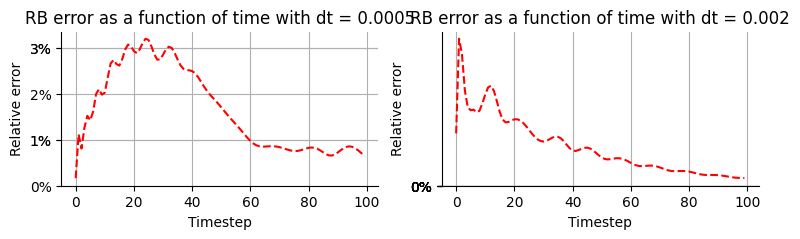

In [ ]:
# Define the parameters for dt = 5e-4 (i.e. dt/2)
dt1 = dt/2
mudt1 = np.array([1000*np.random.rand(), 1000*np.random.rand()])
uRBdt1 = RBsolver(mudt1, dt1, steps)
uFOMdt1 = FOMsolver(mudt1[0], mudt1[1], steps = 99, dt = dt1)

# Define the parameters for dt = 2e-3 (i.e. dt*2)
dt2 = dt*2
mudt2 = np.array([1000*np.random.rand(), 1000*np.random.rand()])
uRBdt2 = RBsolver(mudt2, dt2, steps)
uFOMdt2 = FOMsolver(mudt2[0], mudt2[1], dt = dt2, steps = 99)

# Calculate the error
errordt1 = np.linalg.norm(uFOMdt1-uRBdt1, axis = -1)/np.linalg.norm(uFOMdt1, axis = -1)
errordt2 = np.linalg.norm(uFOMdt2-uRBdt2, axis = -1)/np.linalg.norm(uFOMdt1, axis = -1)


import matplotlib.pyplot as plt
plt.figure(figsize = (9, 2))
plt.subplot(1,2,1)
plt.plot(errordt1, '--r')
plt.xlabel("Timestep")
plt.ylabel("Relative error")
plt.title(f"RB error as a function of time with dt = {dt1}")
marks = np.linspace(errordt1.min(), errordt1.max(), 6)
marks = [round(mark, 2) for mark in marks]
plt.yticks(marks, [num2p(mark).replace(".00", "") for mark in marks])
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.subplot(1,2,2)
plt.plot(errordt2, '--r')
plt.xlabel("Timestep")
plt.ylabel("Relative error")
plt.title(f"RB error as a function of time with dt = {dt2}")
marks2 = np.linspace(errordt2.min(), errordt2.max(), 6)
marks2 = [round(mark, 2) for mark in marks2]
plt.yticks(marks2, [num2p(mark).replace(".00", "") for mark in marks2])
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

## Graphs comparing FOM and ROM

The first row of the plot below shows the solution of FOM, the second row the one of ROM, given the same parameters values, and considering the time instants 1, 50, 90


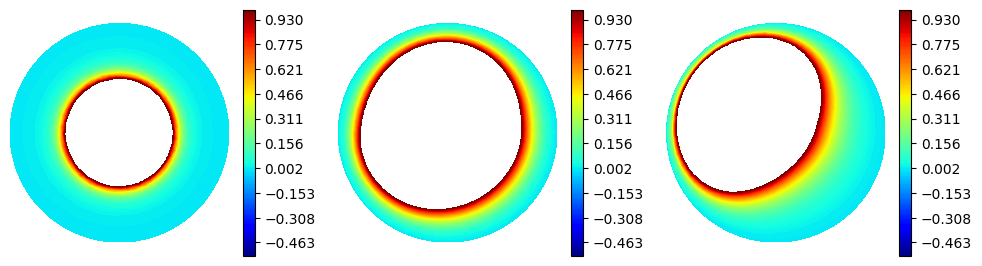

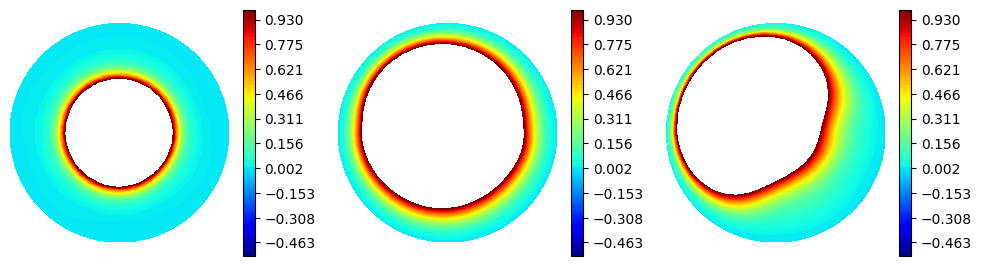

In [ ]:
## Compare the FOM and ROM solutions, looking at some graphs

# Define the parameters and compute the solutions
muplot = np.array([600, 40])
uRB = RBsolver(muplot, dt, steps)
uFOM = FOMsolver(muplot[0], muplot[1])

# Plot a matrix of figures: the first row will show sample 1, 50, 90 of FOM solution; second row will show sample 1, 50, 90 of RB solution
print('The first row of the plot below shows the solution of FOM, the second row the one of ROM, given the same parameters values, and considering the time instants 1, 50, 90')
fe.multiplot(probabilities(uFOM[[1, 50, 90]]), (1, 3), Vh, colorbar = True, vmin = u.min(), vmax = u.max())
fe.multiplot(probabilities(uRB[[1, 50, 90]]), (1, 3), Vh, colorbar = True, vmin = u.min(), vmax = u.max())

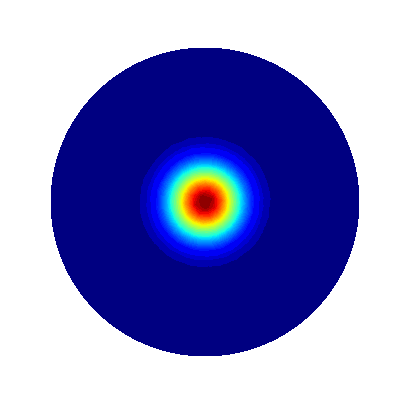

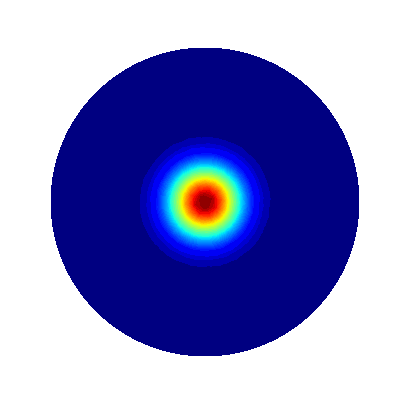

(None, None)

In [ ]:
# Animation plot FOM vs ROM
fe.animate(probabilities(uFOM), Vh), fe.animate(probabilities(uRB), Vh)

# **SAVE THE FILES**

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

#path = 'https://colab.research.google.com/drive/1YwR0vVfvg40a8ffbcryqtKevqeVJJLRM?usp=sharing'

In [ ]:
## Save data
#np.savez("ACassignment1.npz", mu=mu, u=u, Es = Es, Ps = Ps, Es_total = Es_total, Ps_total = Ps_total)

In [ ]:
# data = np.load('ACassignment1.npz')
# print(data.files)

# ________________________________________________________________________________________________________________________________